In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import math
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split

In [5]:
df = pd.read_csv("/content/TATAMOTORS.csv", parse_dates=True, index_col="Date")
df.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2015-01-01,507.50,509.02,494.07,504.47,504.47,10455945
2015-01-02,498.79,506.31,498.55,502.99,502.99,31996486
2015-01-05,508.20,516.08,505.66,508.71,508.71,31190307
2015-01-06,520.36,524.94,510.48,522.22,522.22,10648399
2015-01-07,513.84,522.37,513.84,518.90,518.90,22352205


In [6]:
df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,2870.000000,2870.000000,2870.000000,2870.000000,2870.000000,2.870000e+03
mean,461.095756,468.092686,454.194700,461.161638,461.161638,2.006959e+07
std,274.402518,278.716309,270.259596,274.439498,274.439498,8.623979e+06
min,63.490000,64.950000,62.790000,63.400000,63.400000,5.023439e+06
25%,292.062500,296.200000,287.677500,292.952500,292.952500,1.263248e+07
50%,431.220000,437.110000,424.655000,431.305000,431.305000,2.017597e+07
75%,499.522500,507.567500,491.897500,500.217500,500.217500,2.762993e+07
max,1292.820000,1314.400000,1280.380000,1288.150000,1288.150000,3.499909e+07


In [8]:
print(df.shape)
df.info()

(2870, 6)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2870 entries, 2015-01-01 to 2025-12-31
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       2870 non-null   float64
 1   High       2870 non-null   float64
 2   Low        2870 non-null   float64
 3   Close      2870 non-null   float64
 4   Adj Close  2870 non-null   float64
 5   Volume     2870 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 157.0 KB


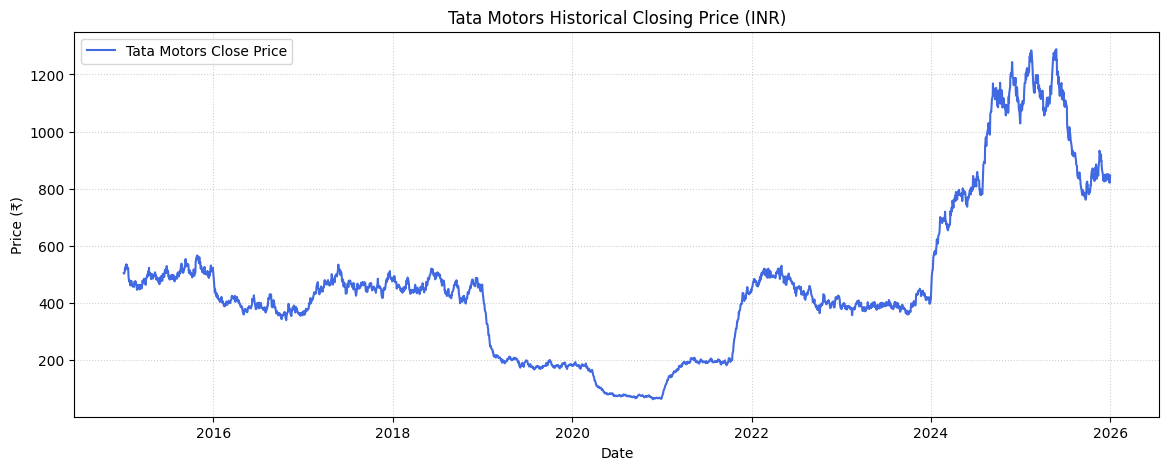

In [9]:
# Data Visualizing

plt.figure(figsize=(14, 5))
plt.plot(df['Close'], color='royalblue', label='Tata Motors Close Price')
plt.title('Tata Motors Historical Closing Price (INR)')
plt.xlabel('Date')
plt.ylabel('Price (₹)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [10]:
# Data Preprocessing

# Extract the target series
data = df[['Close']].values

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

print(f"Total Scaled Records: {len(scaled_data)}")

Total Scaled Records: 2870


In [14]:
# Data Splitting & Tarining :

LOOKBACK = 60
X = []
y = []

for i in range(LOOKBACK, len(scaled_data)):
    X.append(scaled_data[i - LOOKBACK:i, 0])
    y.append(scaled_data[i, 0])

X, y = np.array(X), np.array(y)

# 80% Train, 20% Test (Preserve chronological time ordering)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, shuffle=False
)

# Reshape into 3D tensor: [samples, time_steps, features]
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train shape: (2248, 60, 1), y_train shape: (2248,)
X_test shape: (562, 60, 1), y_test shape: (562,)


In [15]:
# Building the LSTM Architecture :

model = Sequential()

# Layer 1: LSTM with return sequences enabled
model.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(Dropout(0.2))

# Layer 2: LSTM layer returning final hidden state
model.add(LSTM(units=50, return_sequences=False))
model.add(Dropout(0.2))

# Dense output projection
model.add(Dense(units=25))
model.add(Dense(units=1))

# Compile model
model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=40,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/40
64/64 ━━━━━━━━━━━━━━━━━━━━ 11s 91ms/step - loss: 0.0054 - val_loss: 1.1178e-04
Epoch 2/40
64/64 ━━━━━━━━━━━━━━━━━━━━ 10s 85ms/step - loss: 6.7573e-04 - val_loss: 1.1524e-04
Epoch 3/40
64/64 ━━━━━━━━━━━━━━━━━━━━ 11s 98ms/step - loss: 6.1593e-04 - val_loss: 8.5008e-05
Epoch 4/40
64/64 ━━━━━━━━━━━━━━━━━━━━ 5s 78ms/step - loss: 5.1051e-04 - val_loss: 8.4427e-05
Epoch 5/40
64/64 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - loss: 4.4778e-04 - val_loss: 1.0499e-04
Epoch 6/40
64/64 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - loss: 4.1545e-04 - val_loss: 2.0608e-04
Epoch 7/40
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - loss: 3.6903e-04 - val_loss: 1.2221e-04
Epoch 8/40
64/64 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - loss: 3.6179e-04 - val_loss: 7.7984e-05
Epoch 9/40
64/64 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - loss: 2.9642e-04 - val_loss: 7.6167e-05
Epoch 10/40
64/64 ━━━━━━━━━━━━━━━━━━━━ 6s 87ms/step - loss: 2.9700e-04 - val_loss: 1.4773e-04
Epoch 11/40
64/64 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - loss: 2.9520e-0

In [17]:
# Predict on unseen test data
predictions = model.predict(X_test)

# Rescale predictions and ground truth back to INR
predictions = scaler.inverse_transform(predictions)
actual_prices = scaler.inverse_transform(y_test.reshape(-1, 1))

# Calculate metrics
mae = mean_absolute_error(actual_prices, predictions)
mse = mean_squared_error(actual_prices, predictions)
rmse = math.sqrt(mse)

print("=" * 45)
print("     TATA MOTORS MODEL PERFORMANCE         ")
print("=" * 45)
print(f"Mean Absolute Error (MAE):       ₹{mae:.2f}")
print(f"Mean Squared Error (MSE):        {mse:.2f}")
print(f"Root Mean Squared Error (RMSE):  ₹{rmse:.2f}")
print("=" * 45)

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step
     TATA MOTORS MODEL PERFORMANCE         
Mean Absolute Error (MAE):       ₹24.25
Mean Squared Error (MSE):        1024.49
Root Mean Squared Error (RMSE):  ₹32.01


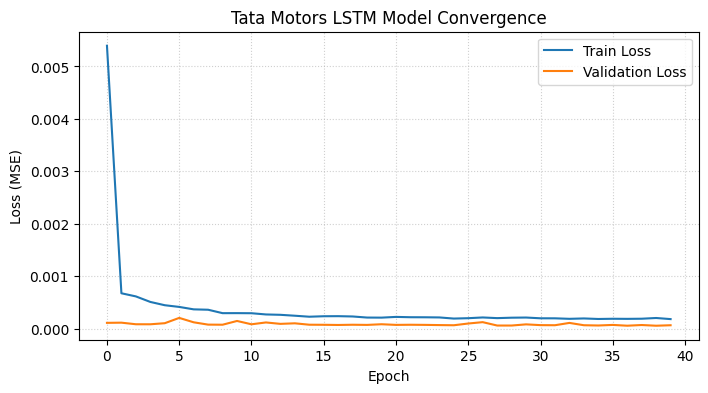

In [18]:
# Plot training & validation loss convergence
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Tata Motors LSTM Model Convergence')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


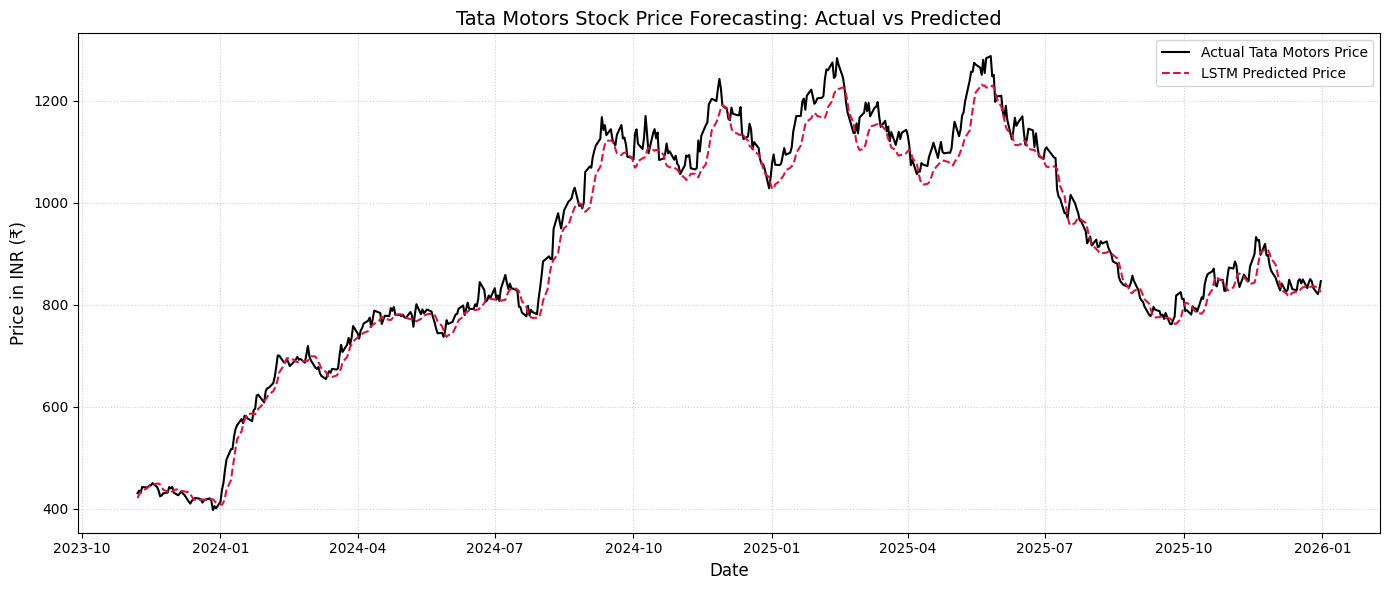

In [19]:
# Plot actual vs predicted prices
train_len = len(X_train) + LOOKBACK
test_dates = df.index[train_len:]

plt.figure(figsize=(14, 6))
plt.plot(test_dates, actual_prices, color='black', label='Actual Tata Motors Price')
plt.plot(test_dates, predictions, color='crimson', linestyle='--', label='LSTM Predicted Price')
plt.title('Tata Motors Stock Price Forecasting: Actual vs Predicted', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price in INR (₹)', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [22]:

model.save("tatamotors_stock_model.keras")

In [23]:
from tensorflow.keras.models import load_model

loaded_model = load_model("tatamotors_stock_model.keras")

loaded_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,705 (373.85 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 63,804 (249.24 KB)